# Unit 3 – Ex 2: Simple linear regression
**Note:** the original notebook calls `stat.linregress` / `stat.pearsonr`, but the import is `from scipy import stats`, so it fails with `NameError`. That's fixed to `stats.` below and nothing else is changed.

Pearsons correlation: -0.759


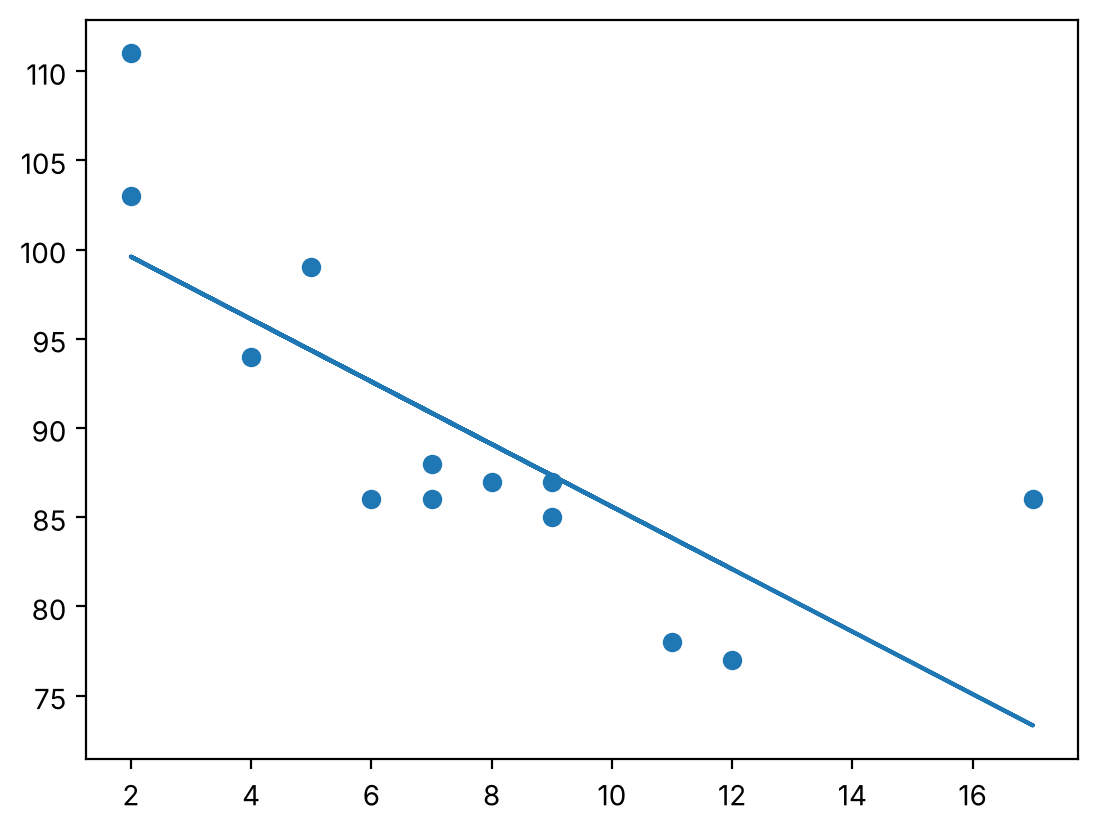

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

slope, intercept, r, p, std_err = stats.linregress(x, y)   # fixed: stat -> stats

corr, _ = stats.pearsonr(x, y)
print('Pearsons correlation: %.3f' % corr)

def myfunc(x):
  return slope * x + intercept

mymodel = list(map(myfunc, x))
plt.scatter(x, y)
plt.plot(x, mymodel)
plt.show()

## Predict Future Values (original)

In [2]:
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]
slope, intercept, r, p, std_err = stats.linregress(x, y)
def myfunc(x):
  return intercept + slope * x
speed = myfunc(10)
print(speed)

85.59308314937454


## Experiments – change the data points and see how slope, r, R² and the prediction at x=10 change

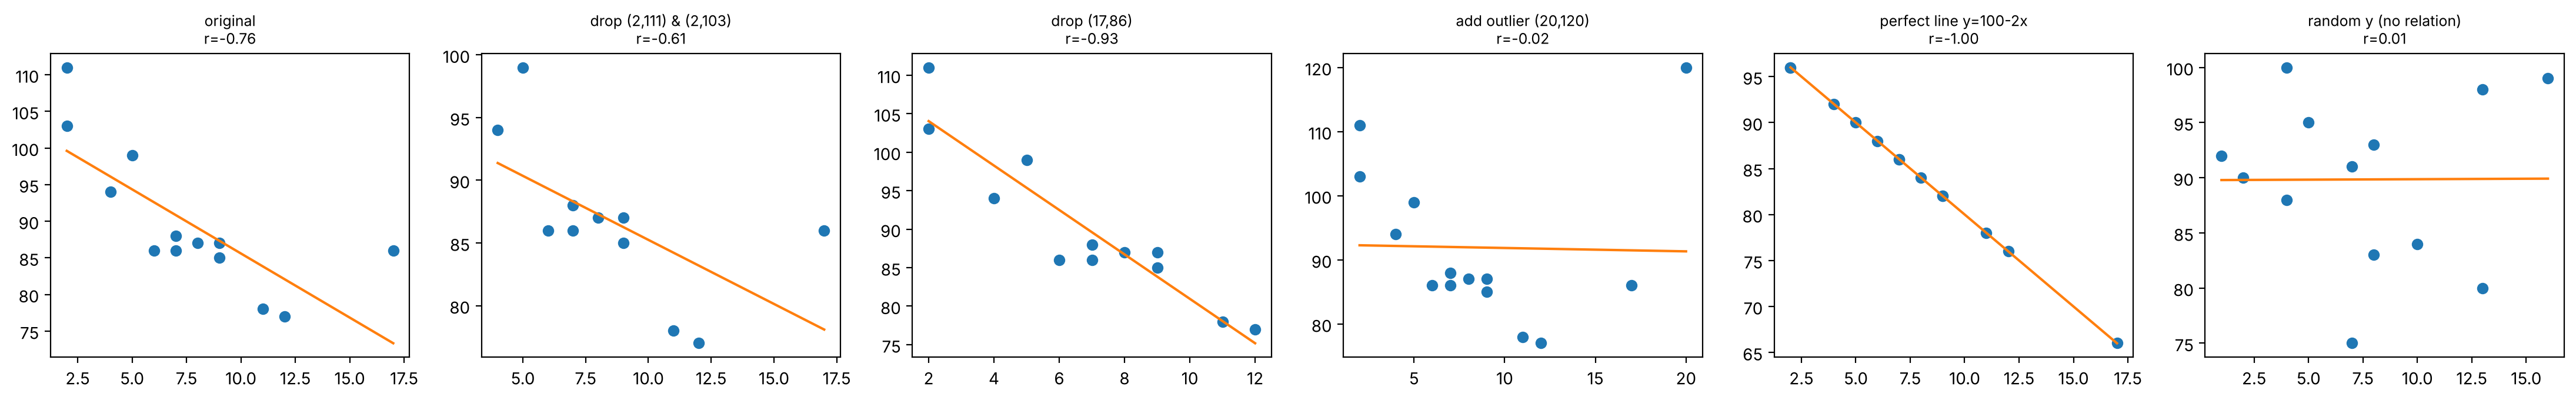

,scenario,n,slope,intercept,r,R²,p-value,pred @ x=10
0,original,13,-1.751,103.106,-0.759,0.575,0.003,85.593
1,"drop (2,111) & (2,103)",11,-1.022,95.459,-0.607,0.369,0.047,85.243
2,"drop (17,86)",12,-2.884,109.792,-0.928,0.860,0.000,80.950
3,"add outlier (20,120)",14,-0.053,92.376,-0.022,0.000,0.940,91.850
4,perfect line y=100-2x,13,-2.000,100.000,-1.000,1.000,0.000,80.000
5,random y (no relation),13,0.009,89.782,0.005,0.000,0.987,89.867


In [3]:
import numpy as np, pandas as pd

base_x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
base_y = [99,86,87,88,111,86,103,87,94,78,77,85,86]
np.random.seed(0)
rx = list(np.random.randint(1, 18, 13))
scen = {
    'original':                          (base_x, base_y),
    'drop (2,111) & (2,103)':            ([a for a,b in zip(base_x,base_y) if a!=2], [b for a,b in zip(base_x,base_y) if a!=2]),
    'drop (17,86)':                      ([a for a,b in zip(base_x,base_y) if a!=17], [b for a,b in zip(base_x,base_y) if a!=17]),
    'add outlier (20,120)':              (base_x+[20], base_y+[120]),
    'perfect line y=100-2x':             (base_x, [100-2*a for a in base_x]),
    'random y (no relation)':            (rx, list(np.random.randint(75, 112, 13))),
}
rows = []
fig, axes = plt.subplots(1, len(scen), figsize=(22, 3.5))
for ax, (name, (xx, yy)) in zip(axes, scen.items()):
    res = stats.linregress(xx, yy)
    rows.append({'scenario': name, 'n': len(xx), 'slope': res.slope, 'intercept': res.intercept,
                 'r': res.rvalue, 'R²': res.rvalue**2, 'p-value': res.pvalue,
                 'pred @ x=10': res.intercept + res.slope*10})
    xs = np.linspace(min(xx), max(xx), 50)
    ax.scatter(xx, yy); ax.plot(xs, res.intercept + res.slope*xs, c='C1')
    ax.set_title(f'{name}\nr={res.rvalue:.2f}', fontsize=9)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

### What changed
* The original fit is weak (r ≈ -0.76, R² ≈ 0.58). The two points at x=2 (111 and 103) do a lot of the work.
* **Dropping the two x=2 points** almost halves the slope (-1.75 → -1.02) and r falls to -0.61. The prediction at x=10 hardly moves, because x=10 is near the middle of the data where every fitted line passes close by. With only 13 points, a couple of high-leverage values decide the slope.
* **Dropping (17, 86)** – the point far out on the right – makes the line *steeper*, so that point was pulling it flat.
* **One outlier at (20,120)** flattens the slope to about 0 and drops r from -0.76 to about 0. A single point erases the whole relationship.
* **A perfect line** gives r = -1 and p ≈ 0. **Random y** gives r near 0 and a large p-value, so predicting from it would be meaningless.